In [179]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

In [132]:
df = pd.read_csv("cars.csv")

In [133]:
df.head()

,brand,km_driven,fuel,owner,selling_price
0,Maruti,145500,Diesel,First Owner,450000
1,Skoda,120000,Diesel,Second Owner,370000
2,Honda,140000,Petrol,Third Owner,158000
3,Hyundai,127000,Diesel,First Owner,225000
4,Maruti,120000,Petrol,First Owner,130000


In [134]:
df['brand'].value_counts()

brand
Maruti           2448
Hyundai          1415
Mahindra          772
Tata              734
Toyota            488
Honda             467
Ford              397
Chevrolet         230
Renault           228
Volkswagen        186
BMW               120
Skoda             105
Nissan             81
Jaguar             71
Volvo              67
Datsun             65
Mercedes-Benz      54
Fiat               47
Audi               40
Lexus              34
Jeep               31
Mitsubishi         14
Land                6
Force               6
Isuzu               5
Kia                 4
Ambassador          4
MG                  3
Daewoo              3
Ashok               1
Opel                1
Peugeot             1
Name: count, dtype: int64

In [135]:
df['brand'].nunique()

32

In [136]:
df['fuel'].nunique()

4

In [137]:
df['fuel'].value_counts()

fuel
Diesel    4402
Petrol    3631
CNG         57
LPG         38
Name: count, dtype: int64

In [138]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(df.iloc[:,0:4],df.iloc[:,-1],test_size=0.2,random_state=42)


In [139]:
x_train

,brand,km_driven,fuel,owner
6518,Tata,2560,Petrol,First Owner
6144,Honda,80000,Petrol,Second Owner
6381,Hyundai,150000,Diesel,Fourth & Above Owner
438,Maruti,120000,Diesel,Second Owner
5939,Maruti,25000,Petrol,First Owner
...,...,...,...,...
5226,Mahindra,120000,Diesel,First Owner
5390,Maruti,80000,Diesel,Second Owner
860,Hyundai,35000,Petrol,First Owner
7603,Maruti,27000,Diesel,First Owner


In [140]:
x_test

,brand,km_driven,fuel,owner
1971,Honda,110000,Petrol,Third Owner
4664,Tata,291977,Diesel,First Owner
5448,Maruti,70000,Diesel,First Owner
3333,Honda,120000,Petrol,Second Owner
2316,Maruti,69000,Diesel,Second Owner
...,...,...,...,...
1149,BMW,8500,Diesel,First Owner
5002,Maruti,40000,Petrol,First Owner
6008,Hyundai,54043,Petrol,First Owner
2283,Tata,70000,Petrol,First Owner


In [141]:
df

,brand,km_driven,fuel,owner,selling_price
0,Maruti,145500,Diesel,First Owner,450000
1,Skoda,120000,Diesel,Second Owner,370000
2,Honda,140000,Petrol,Third Owner,158000
3,Hyundai,127000,Diesel,First Owner,225000
4,Maruti,120000,Petrol,First Owner,130000
...,...,...,...,...,...
8123,Hyundai,110000,Petrol,First Owner,320000
8124,Hyundai,119000,Diesel,Fourth & Above Owner,135000
8125,Maruti,120000,Diesel,First Owner,382000
8126,Tata,25000,Diesel,First Owner,290000


In [142]:
from sklearn.preprocessing import OneHotEncoder


In [143]:
ohe = OneHotEncoder(sparse_output = False,dtype = np.int32)

In [144]:
x_train_new = ohe.fit_transform(x_train[["fuel","owner"]])

In [145]:
x_test_new = ohe.transform(x_test[['fuel','owner']])

In [146]:
x_train_new

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 1, 0, 0],
       [0, 1, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 1, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 1, 0, 0]], shape=(6502, 9), dtype=int32)

In [147]:
x_train[['brand','km_driven']].values

array([['Tata', 2560],
       ['Honda', 80000],
       ['Hyundai', 150000],
       ...,
       ['Hyundai', 35000],
       ['Maruti', 27000],
       ['Maruti', 70000]], shape=(6502, 2), dtype=object)

In [148]:
np.hstack((x_train[['brand','km_driven']].values,x_train_new))

array([['Tata', 2560, 0, ..., 0, 0, 0],
       ['Honda', 80000, 0, ..., 1, 0, 0],
       ['Hyundai', 150000, 0, ..., 0, 0, 0],
       ...,
       ['Hyundai', 35000, 0, ..., 0, 0, 0],
       ['Maruti', 27000, 0, ..., 0, 0, 0],
       ['Maruti', 70000, 0, ..., 1, 0, 0]], shape=(6502, 11), dtype=object)

In [149]:
df["brand"].value_counts()

brand
Maruti           2448
Hyundai          1415
Mahindra          772
Tata              734
Toyota            488
Honda             467
Ford              397
Chevrolet         230
Renault           228
Volkswagen        186
BMW               120
Skoda             105
Nissan             81
Jaguar             71
Volvo              67
Datsun             65
Mercedes-Benz      54
Fiat               47
Audi               40
Lexus              34
Jeep               31
Mitsubishi         14
Land                6
Force               6
Isuzu               5
Kia                 4
Ambassador          4
MG                  3
Daewoo              3
Ashok               1
Opel                1
Peugeot             1
Name: count, dtype: int64

In [150]:
df.info(
)

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   brand          8128 non-null   str  
 1   km_driven      8128 non-null   int64
 2   fuel           8128 non-null   str  
 3   owner          8128 non-null   str  
 4   selling_price  8128 non-null   int64
dtypes: int64(2), str(3)
memory usage: 317.6 KB


In [151]:
X = df.drop(columns = "selling_price")
Y = df["selling_price"]
Y

0       450000
1       370000
2       158000
3       225000
4       130000
         ...  
8123    320000
8124    135000
8125    382000
8126    290000
8127    290000
Name: selling_price, Length: 8128, dtype: int64

In [152]:
d =X.select_dtypes(include= 'str').columns

In [153]:
d

Index(['brand', 'fuel', 'owner'], dtype='str')

In [154]:
df['brand'].nunique()

32

In [155]:
encoded_value = ohe.fit_transform(x_train[d])

In [156]:
encoded_value

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 1, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 1, 0, 0]], shape=(6502, 41), dtype=int32)

In [157]:
y_train.shape

(6502,)

In [158]:
encoded_value

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 1, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 1, 0, 0]], shape=(6502, 41), dtype=int32)

In [159]:
y_train

y_train = pd.DataFrame(y_train, columns=['selling_price'])

In [160]:
# y_train = y_train.values.reshape(-1, 1)

# y_train[["selling_price"]]   to change twod df

In [161]:
y_train.shape
y_train

,selling_price
6518,520000
6144,300000
6381,380000
438,530000
5939,335000
...,...
5226,475000
5390,530000
860,576000
7603,770000


In [162]:
e_column = ohe.get_feature_names_out()

In [163]:
# f = np.hstack((encoded_value,y_train))

In [164]:
f = pd.DataFrame(data=encoded_value,columns=e_column)

In [165]:
f

,brand_Ambassador,brand_Ashok,brand_Audi,brand_BMW,brand_Chevrolet,brand_Daewoo,brand_Datsun,brand_Fiat,brand_Force,brand_Ford,...,brand_Volvo,fuel_CNG,fuel_Diesel,fuel_LPG,fuel_Petrol,owner_First Owner,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,1,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,1,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,1,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6497,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,1,0,0,0,0
6498,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,1,0,0
6499,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,1,0,0,0,0
6500,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,1,0,0,0,0


In [169]:
np.hstack((f,y_train))

array([[     0,      0,      0, ...,      0,      0, 520000],
       [     0,      0,      0, ...,      0,      0, 300000],
       [     0,      0,      0, ...,      0,      0, 380000],
       ...,
       [     0,      0,      0, ...,      0,      0, 576000],
       [     0,      0,      0, ...,      0,      0, 770000],
       [     0,      0,      0, ...,      0,      0, 155000]],
      shape=(6502, 42))

In [170]:
import pandas as pd
import numpy as np

combined = np.hstack((f, y_train.to_numpy().reshape(-1, 1)))

columns = list(e_column) + ['selling_price']

df = pd.DataFrame(combined, columns=columns)

df.head()

,brand_Ambassador,brand_Ashok,brand_Audi,brand_BMW,brand_Chevrolet,brand_Daewoo,brand_Datsun,brand_Fiat,brand_Force,brand_Ford,...,fuel_CNG,fuel_Diesel,fuel_LPG,fuel_Petrol,owner_First Owner,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner,selling_price
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,1,0,0,0,0,520000
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,1,0,0,300000
2,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,380000
3,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,1,0,0,530000
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,1,0,0,0,0,335000


In [172]:
x = df.drop(columns='selling_price')
y = df['selling_price']

In [173]:
xtrain,xtest,ytrain,ytest = train_test_split(
    x,
    y,
    train_size=0.8,
    random_state=42
)

In [ ]:
model = LinearRegression()

In [174]:
model.fit(xtrain,ytrain)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [175]:
model.intercept_

np.float64(1498943.19998595)

In [176]:
model.coef_

array([-1.09728698e+06, -6.40284270e-10,  8.84112746e+05,  2.88829324e+06,
       -9.74030547e+05, -1.23500845e+06, -9.61118293e+05, -9.73718484e+05,
       -4.91654393e+05, -8.06417499e+05, -6.88747073e+05, -8.07843736e+05,
        1.10161898e+05,  1.42945079e+06,  6.45918147e+05,  3.96618977e+04,
        2.03120875e+06,  3.83799155e+06,  4.87991549e+05, -7.31231312e+05,
       -8.59785287e+05,  1.36674441e+06, -5.70494895e+05, -8.46754345e+05,
       -9.13774190e+05, -4.65661287e-10, -8.67526468e+05, -6.76030435e+05,
       -9.70386509e+05, -3.71453268e+05, -7.93098725e+05,  1.91482592e+06,
       -5.50801565e+04,  1.62886931e+05, -1.17864055e+05,  1.00572798e+04,
       -1.96992029e+05, -5.52039180e+05, -4.54043155e+05,  1.73030065e+06,
       -5.27226290e+05])

In [177]:
ytrain_predicted = model.predict(xtrain)

ValueError: x and y must be the same size

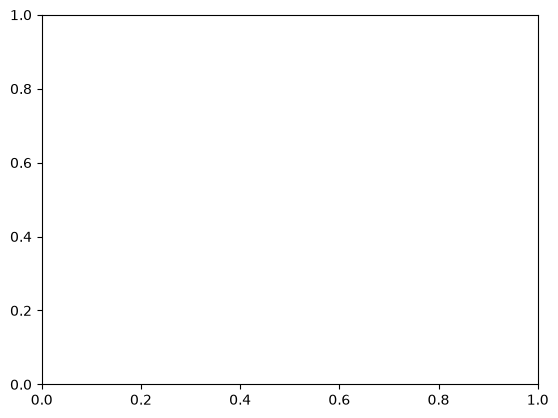

In [180]:
plt.scatter(xtrain,ytrain)  # actual input vs actual output
plt.scatter(xtrain,ytrain_predicted)  # actual input vs predicted output